# Inventory Replenishment Agent

This notebook loads sales, inventory, and policy CSV files. It uses an EWMA forecast and simulates replenishment decisions for three SKUs.

## Agent Goal and Design

The Inventory Replenishment Agent recommends when and how much inventory to order for each SKU. Its main goal is to reduce stockouts while controlling total inventory cost.

The agent uses the following inputs:

- Daily sales demand from `sales.csv`
- Opening inventory from `inventory.csv`
- Unit cost, holding cost, stockout cost, lead time, minimum order quantity, and service level from `params.csv`
- EWMA demand forecasts and forecast error

Each day, the agent outputs either an order quantity or a WAIT decision. The agent also records the reason for each decision in a daily log.

The agent calculates a reorder point using expected demand during the lead time, a review period, and safety stock. Safety stock protects against demand uncertainty and is based on the selected service level.


## 1. Prepare demand and EWMA forecasts

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

sales = pd.read_csv("sales.csv", parse_dates=["date"])
inventory = pd.read_csv("inventory.csv")
params = pd.read_csv("params.csv")

sales = sales.sort_values(["date", "sku"]).reset_index(drop=True)

display(sales.head())
display(inventory)
display(params)

,date,sku,qty_sold
0,2026-01-01,SKU-A,8
1,2026-01-01,SKU-B,15
2,2026-01-01,SKU-C,5
3,2026-01-02,SKU-A,11
4,2026-01-02,SKU-B,15


,sku,opening_stock
0,SKU-A,80
1,SKU-B,140
2,SKU-C,55


,sku,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level
0,SKU-A,12.5,0.08,25.0,5,40,0.95
1,SKU-B,8.0,0.05,18.0,7,70,0.90
2,SKU-C,22.0,0.12,35.0,4,25,0.95


In [18]:
MAX_COVER_DAYS = 30

In [19]:
daily = (
    sales.groupby(["date", "sku"], as_index=False)["qty_sold"]
    .sum()
    .sort_values(["sku", "date"])
)

alpha = 0.30
daily["forecast"] = (
    daily.groupby("sku")["qty_sold"]
    .transform(lambda x: x.shift(1).ewm(alpha=alpha, adjust=False).mean())
)

daily["forecast"] = daily["forecast"].fillna(
    daily.groupby("sku")["qty_sold"].transform("mean")
)
daily["forecast_error"] = daily["qty_sold"] - daily["forecast"]

error_stats = (
    daily.groupby("sku")["forecast_error"]
    .std()
    .reset_index(name="forecast_error_std")
)

policy = params.merge(error_stats, on="sku")
policy["forecast_error_std"] = policy["forecast_error_std"].fillna(0)
policy["z_score"] = policy["service_level"].apply(norm.ppf)
policy["safety_stock"] = policy["z_score"] * policy["forecast_error_std"]

display(daily.head(10))
display(policy)

,date,sku,qty_sold,forecast,forecast_error
0,2026-01-01,SKU-A,8,8.011111,-0.011111
3,2026-01-02,SKU-A,11,8.000000,3.000000
6,2026-01-03,SKU-A,6,8.900000,-2.900000
9,2026-01-04,SKU-A,6,8.030000,-2.030000
12,2026-01-05,SKU-A,8,7.421000,0.579000
15,2026-01-06,SKU-A,10,7.594700,2.405300
18,2026-01-07,SKU-A,8,8.316290,-0.316290
21,2026-01-08,SKU-A,8,8.221403,-0.221403
24,2026-01-09,SKU-A,11,8.154982,2.845018
27,2026-01-10,SKU-A,6,9.008487,-3.008487


,sku,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level,forecast_error_std,z_score,safety_stock
0,SKU-A,12.5,0.08,25.0,5,40,0.95,1.920407,1.644854,3.158789
1,SKU-B,8.0,0.05,18.0,7,70,0.90,2.851229,1.281552,3.653997
2,SKU-C,22.0,0.12,35.0,4,25,0.95,1.171177,1.644854,1.926415


## 2. Run the daily agent simulation

The agent orders when inventory position falls below the reorder point. It respects each SKU's minimum order quantity and records a rationale for every decision.

In [20]:
policy_by_sku = policy.set_index("sku").to_dict("index")
opening = inventory.set_index("sku")["opening_stock"].to_dict()
skus = sorted(daily["sku"].unique())
dates = sorted(daily["date"].unique())

on_hand = {sku: float(opening[sku]) for sku in skus}
pipeline = []
log = []

for current_date in dates:
    arrivals = [p for p in pipeline if p["arrival_date"] == current_date]
    for p in arrivals:
        on_hand[p["sku"]] += p["quantity"]
    pipeline = [p for p in pipeline if p["arrival_date"] != current_date]

    for _, row in daily[daily["date"] == current_date].iterrows():
        sku = row["sku"]
        p = policy_by_sku[sku]
        demand_qty = float(row["qty_sold"])
        forecast = max(float(row["forecast"]), 0)
        starting_stock = on_hand[sku]

        fulfilled = min(starting_stock, demand_qty)
        stockout = demand_qty - fulfilled
        on_hand[sku] -= fulfilled

        lead_time = int(p["lead_time_days"])
        min_qty = int(p["min_order_qty"])
        safety_stock = float(p["safety_stock"])

        on_order = sum(
            item["quantity"] for item in pipeline if item["sku"] == sku
        )
        inventory_position = on_hand[sku] + on_order
        review_period = 1

        reorder_point = (
            forecast * (lead_time + review_period) + safety_stock
        )

        if inventory_position < reorder_point:
            target = reorder_point
            raw_order_quantity = max(
                0,
                int(np.ceil(target - inventory_position))
            )

            if raw_order_quantity > 0:
                order_qty = max(min_qty, raw_order_quantity)
                max_inventory_level = (
                    forecast * MAX_COVER_DAYS + safety_stock
                )
                max_allowed_order = max(
                    min_qty,
                    int(np.ceil(max_inventory_level - inventory_position))
                )
                order_qty = min(
                    order_qty,
                    max_allowed_order
                )
            else:
                order_qty = 0

            pipeline.append({
                "sku": sku,
                "quantity": order_qty,
                "arrival_date": current_date + pd.Timedelta(days=lead_time)
            })
            action = "ORDER"
            rationale = (
                f"Position {inventory_position:.1f} is below "
                f"reorder point {reorder_point:.1f}."
            )
        else:
            order_qty = 0
            action = "WAIT"
            rationale = (
                f"Position {inventory_position:.1f} is above "
                f"reorder point {reorder_point:.1f}."
            )

        log.append({
            "date": current_date,
            "sku": sku,
            "actual_demand": demand_qty,
            "forecast": forecast,
            "starting_stock": starting_stock,
            "units_fulfilled": fulfilled,
            "stockout_units": stockout,
            "ending_stock": on_hand[sku],
            "inventory_position": inventory_position,
            "reorder_point": reorder_point,
            "order_quantity": order_qty,
            "action": action,
            "rationale": rationale,
            "holding_cost": on_hand[sku] * p["holding_cost_per_day"],
            "stockout_cost": stockout * p["stockout_cost"],
            "purchase_cost": order_qty * p["unit_cost"]
        })

agent_log = pd.DataFrame(log)
display(agent_log.head(30))
agent_log.to_csv("agent_log.csv", index=False)

,date,sku,actual_demand,forecast,starting_stock,units_fulfilled,stockout_units,ending_stock,inventory_position,reorder_point,order_quantity,action,rationale,holding_cost,stockout_cost,purchase_cost
0,2026-01-01,SKU-A,8.0,8.011111,80.0,8.0,0.0,72.0,72.0,51.225455,0,WAIT,Position 72.0 is above reorder point 51.2.,5.76,0.0,0.0
1,2026-01-01,SKU-B,15.0,14.466667,140.0,15.0,0.0,125.0,125.0,119.387330,0,WAIT,Position 125.0 is above reorder point 119.4.,6.25,0.0,0.0
2,2026-01-01,SKU-C,5.0,5.066667,55.0,5.0,0.0,50.0,50.0,27.259748,0,WAIT,Position 50.0 is above reorder point 27.3.,6.00,0.0,0.0
3,2026-01-02,SKU-A,11.0,8.000000,72.0,11.0,0.0,61.0,61.0,51.158789,0,WAIT,Position 61.0 is above reorder point 51.2.,4.88,0.0,0.0
4,2026-01-02,SKU-B,15.0,15.000000,125.0,15.0,0.0,110.0,110.0,123.653997,70,ORDER,Position 110.0 is below reorder point 123.7.,5.50,0.0,560.0
5,2026-01-02,SKU-C,5.0,5.000000,50.0,5.0,0.0,45.0,45.0,26.926415,0,WAIT,Position 45.0 is above reorder point 26.9.,5.40,0.0,0.0
6,2026-01-03,SKU-A,6.0,8.900000,61.0,6.0,0.0,55.0,55.0,56.558789,40,ORDER,Position 55.0 is below reorder point 56.6.,4.40,0.0,500.0
7,2026-01-03,SKU-B,11.0,15.000000,110.0,11.0,0.0,99.0,169.0,123.653997,0,WAIT,Position 169.0 is above reorder point 123.7.,4.95,0.0,0.0
8,2026-01-03,SKU-C,4.0,5.000000,45.0,4.0,0.0,41.0,41.0,26.926415,0,WAIT,Position 41.0 is above reorder point 26.9.,4.92,0.0,0.0
9,2026-01-04,SKU-A,6.0,8.030000,55.0,6.0,0.0,49.0,89.0,51.338789,0,WAIT,Position 89.0 is above reorder point 51.3.,3.92,0.0,0.0


## 3. Evaluate the agent

In [21]:
# Agent metrics by SKU
summary = (
    agent_log.groupby("sku")
    .agg(
        total_demand=("actual_demand", "sum"),
        units_fulfilled=("units_fulfilled", "sum"),
        stockout_units=("stockout_units", "sum"),
        orders_placed=("order_quantity", lambda x: int((x > 0).sum())),
        holding_cost=("holding_cost", "sum"),
        stockout_cost=("stockout_cost", "sum"),
        purchase_cost=("purchase_cost", "sum")
    )
    .reset_index()
)

summary["fill_rate"] = (
    summary["units_fulfilled"] / summary["total_demand"]
)
summary["operating_cost"] = (
    summary["holding_cost"] + summary["stockout_cost"]
)
summary["total_cost"] = (
    summary["operating_cost"] + summary["purchase_cost"]
)

# Simple baseline: average historical demand and a fixed reorder point.
def run_baseline(daily, policy, inventory):
    policy_by_sku = policy.set_index("sku").to_dict("index")
    opening = inventory.set_index("sku")["opening_stock"].to_dict()
    average_demand = daily.groupby("sku")["qty_sold"].mean().to_dict()

    on_hand = {sku: float(opening[sku]) for sku in skus}
    pipeline = []
    baseline_rows = []

    for current_date in dates:
        arrivals = [
            order for order in pipeline
            if order["arrival_date"] == current_date
        ]
        for order in arrivals:
            on_hand[order["sku"]] += order["quantity"]
        pipeline = [
            order for order in pipeline
            if order["arrival_date"] != current_date
        ]

        for _, row in daily[daily["date"] == current_date].iterrows():
            sku = row["sku"]
            p = policy_by_sku[sku]
            demand_qty = float(row["qty_sold"])

            fulfilled = min(on_hand[sku], demand_qty)
            stockout = demand_qty - fulfilled
            on_hand[sku] -= fulfilled

            lead_time = int(p["lead_time_days"])
            min_qty = int(p["min_order_qty"])
            safety_stock = float(p["safety_stock"])
            on_order = sum(
                order["quantity"]
                for order in pipeline
                if order["sku"] == sku
            )
            inventory_position = on_hand[sku] + on_order

            baseline_rop = (
                average_demand[sku] * (lead_time + 1)
                + safety_stock
            )

            if inventory_position < baseline_rop:
                order_qty = max(
                    min_qty,
                    int(np.ceil(baseline_rop - inventory_position))
                )
                pipeline.append({
                    "sku": sku,
                    "quantity": order_qty,
                    "arrival_date": (
                        current_date
                        + pd.Timedelta(days=lead_time)
                    )
                })
                action = "ORDER"
            else:
                order_qty = 0
                action = "WAIT"

            baseline_rows.append({
                "date": current_date,
                "sku": sku,
                "actual_demand": demand_qty,
                "units_fulfilled": fulfilled,
                "stockout_units": stockout,
                "ending_stock": on_hand[sku],
                "order_quantity": order_qty,
                "action": action,
                "holding_cost": (
                    on_hand[sku] * p["holding_cost_per_day"]
                ),
                "stockout_cost": stockout * p["stockout_cost"],
                "purchase_cost": order_qty * p["unit_cost"]
            })

    return pd.DataFrame(baseline_rows)

baseline_log = run_baseline(daily, policy, inventory)

baseline_totals = {
    "policy": "Baseline",
    "stockout_units": baseline_log["stockout_units"].sum(),
    "fill_rate": (
        baseline_log["units_fulfilled"].sum()
        / baseline_log["actual_demand"].sum()
    ),
    "holding_cost": baseline_log["holding_cost"].sum(),
    "stockout_cost": baseline_log["stockout_cost"].sum(),
    "purchase_cost": baseline_log["purchase_cost"].sum()
}
baseline_totals["operating_cost"] = (
    baseline_totals["holding_cost"]
    + baseline_totals["stockout_cost"]
)
baseline_totals["total_cost"] = (
    baseline_totals["operating_cost"]
    + baseline_totals["purchase_cost"]
)

agent_totals = {
    "policy": "EWMA Agent",
    "stockout_units": agent_log["stockout_units"].sum(),
    "fill_rate": (
        agent_log["units_fulfilled"].sum()
        / agent_log["actual_demand"].sum()
    ),
    "holding_cost": agent_log["holding_cost"].sum(),
    "stockout_cost": agent_log["stockout_cost"].sum(),
    "purchase_cost": agent_log["purchase_cost"].sum()
}
agent_totals["operating_cost"] = (
    agent_totals["holding_cost"]
    + agent_totals["stockout_cost"]
)
agent_totals["total_cost"] = (
    agent_totals["operating_cost"]
    + agent_totals["purchase_cost"]
)

comparison = pd.DataFrame([baseline_totals, agent_totals])

total = pd.DataFrame([{
    "sku": "ALL SKUs",
    "total_demand": summary["total_demand"].sum(),
    "units_fulfilled": summary["units_fulfilled"].sum(),
    "stockout_units": summary["stockout_units"].sum(),
    "orders_placed": summary["orders_placed"].sum(),
    "holding_cost": summary["holding_cost"].sum(),
    "stockout_cost": summary["stockout_cost"].sum(),
    "purchase_cost": summary["purchase_cost"].sum(),
    "operating_cost": summary["operating_cost"].sum(),
    "fill_rate": (
        summary["units_fulfilled"].sum()
        / summary["total_demand"].sum()
    ),
    "total_cost": summary["total_cost"].sum()
}])

summary = pd.concat([summary, total], ignore_index=True)

print("Agent results by SKU:")
display(summary)

print("Baseline versus EWMA agent:")
display(comparison)

,sku,total_demand,units_fulfilled,stockout_units,orders_placed,holding_cost,stockout_cost,purchase_cost,fill_rate,total_cost
0,SKU-A,721.0,721.0,0.0,18,240.88,0.0,9000.0,1.0,9240.88
1,SKU-B,1302.0,1302.0,0.0,19,250.75,0.0,10640.0,1.0,10890.75
2,SKU-C,456.0,456.0,0.0,18,224.16,0.0,9900.0,1.0,10124.16
3,ALL SKUs,2479.0,2479.0,0.0,55,715.79,0.0,29540.0,1.0,30255.79


## Baseline Comparison

The baseline uses average historical demand and a fixed reorder point. The EWMA agent uses recent demand information, allowing it to respond more quickly to changes in demand.

The policies are compared using stockout units, fill rate, holding cost, stockout cost, operating cost, purchase cost, and total cost. A lower stockout count and higher fill rate indicate better service performance. Lower total cost indicates better cost efficiency.


## Trade-Off Reflection

The agent must balance inventory availability with inventory cost. Holding more inventory can reduce stockouts and improve fill rate, but it increases holding costs and ties up working capital.

Ordering too little may reduce costs in the short term, but it can cause stockouts, lost sales, and lower customer trust. Ordering too much can prevent stockouts but create excess inventory.

The service level and safety stock create a balance between these risks. A higher service level provides more protection against stockouts but usually requires more inventory. A lower service level reduces holding costs but increases the chance of unmet demand.

## 4. Visualize inventory levels and order decisions

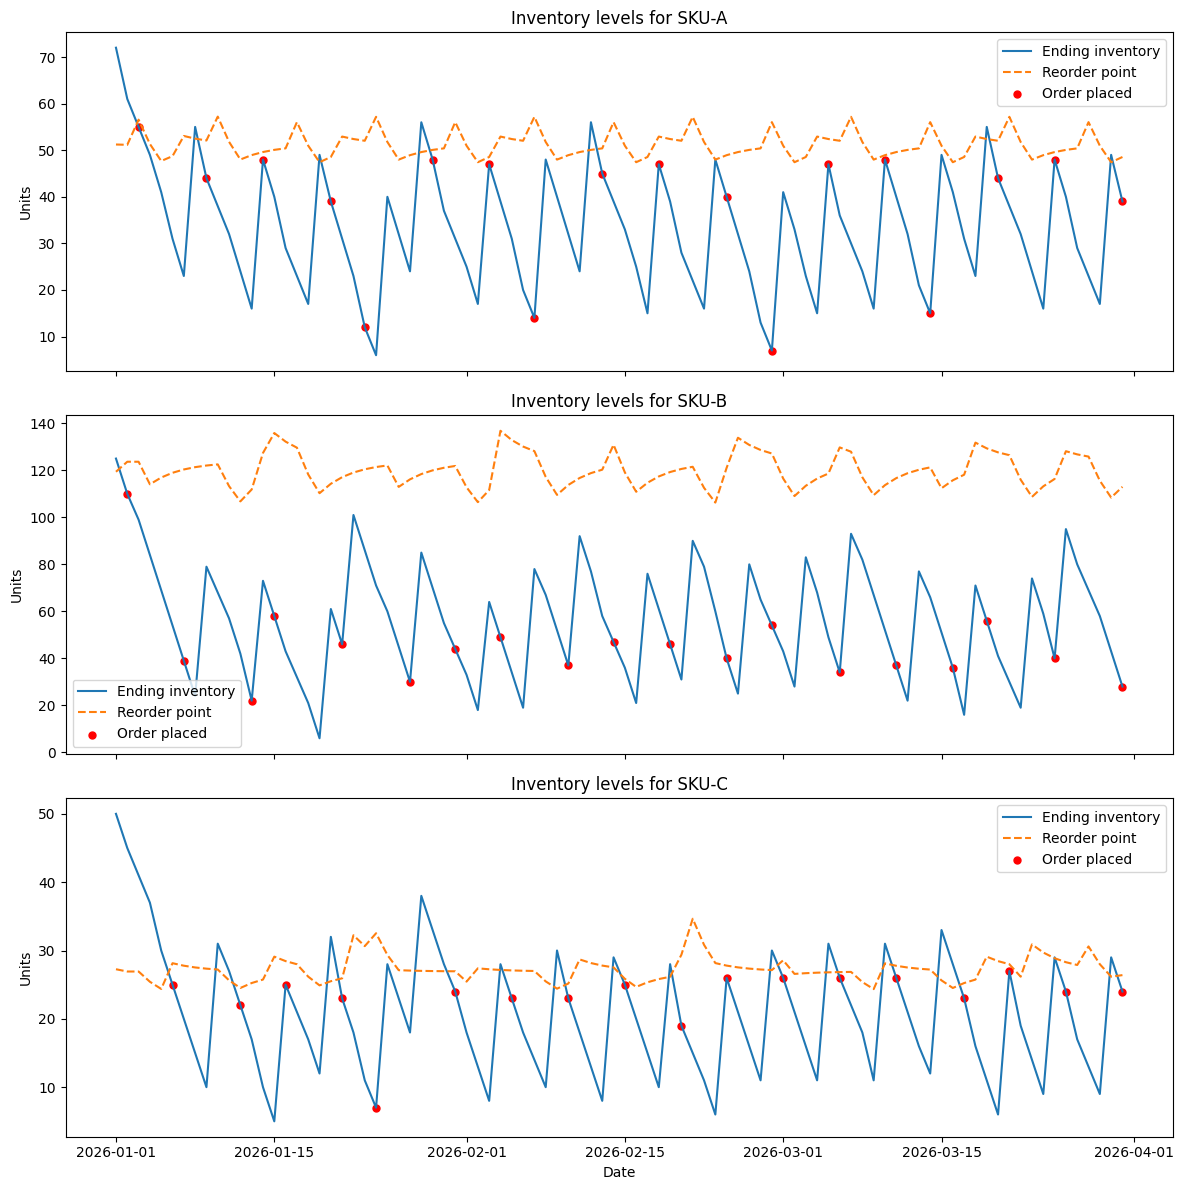

In [22]:
fig, axes = plt.subplots(
    len(skus), 1, figsize=(12, 4 * len(skus)), sharex=True
)
axes = np.atleast_1d(axes)

for ax, sku in zip(axes, skus):
    sku_log = agent_log[agent_log["sku"] == sku]
    ax.plot(sku_log["date"], sku_log["ending_stock"], label="Ending inventory")
    ax.plot(sku_log["date"], sku_log["reorder_point"], "--", label="Reorder point")

    orders = sku_log[sku_log["order_quantity"] > 0]
    ax.scatter(
        orders["date"], orders["ending_stock"],
        color="red", s=25, label="Order placed"
    )

    ax.set_title(f"Inventory levels for {sku}")
    ax.set_ylabel("Units")
    ax.legend()

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

## Scaling Note

This agent could run as a scheduled cloud job once per day after updated sales data becomes available. The job would load the latest CSV files, generate forecasts, create purchase order recommendations, and save the daily decision log.

Monitoring should track fill rate, stockout units, forecast error, inventory levels, number of purchase orders, and total cost. Alerts could notify managers when fill rate falls below the target service level or when inventory becomes unusually high or low.

For reliability, the system should check that all required files and columns exist before running. It should also handle missing dates, missing SKU values, duplicate records, and temporary data-loading failures.

Cost controls should include maximum order quantities, inventory caps, approval requirements for unusually large orders, and tracking of working capital tied up in inventory.

## Conclusion

The agent forecasts demand with EWMA, calculates safety stock from forecast error and service level, places orders based on projected inventory, respects minimum order quantities, and reports stockouts, fill rate, and total cost.